# 4. Gradient Boosting

Adds 300 small trees one after another; each tree is fitted to the gradient of the log loss (what the
current ensemble still gets wrong) and added with a learning rate of 0.05. Each tree sees 80% of the rows.
The validation loss stops the boosting early.

From-scratch code: `ClassificationAlgorithms/GradientBoosting.py` · charts: `Images/Classification/04_Gradient_Boosting/` · tables: `Results/Classification/04_Gradient_Boosting/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from GradientBoosting import GradientBoostingClassifierScratch
from sklearn.ensemble import GradientBoostingClassifier

out = Outputs("Classification", "04_Gradient_Boosting")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = GradientBoostingClassifierScratch(
    n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED
)
check_settings("Gradient Boosting", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn GradientBoostingClassifier with the same settings
sk = GradientBoostingClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED
).fit(d.X_tr, d.y_tr)
p_sk = sk.predict_proba(d.X_te)[:, 1]
check = sklearn_check(
    "Gradient Boosting vs sklearn GradientBoostingClassifier",
    np.abs(p_te - p_sk).max(),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, p_sk),
    "max |dP|",
)

settings match Common/model_zoo.py (11 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2659        0.5000
log loss                            0.4590           NaN
accuracy                            0.5172        0.8184
precision                           0.2227        0.3307
recall / sensitivity                0.8164        0.1377
specificity                         0.4606           NaN
F1                                  0.3500        0.1944
ROC-AUC                             0.6928           NaN
PR-AUC                              0.2790           NaN
defaulters missed (FN)             56.0000           NaN

catches 81.6% of the 305 test defaulters (56 missed), flags 58.4% of applicants


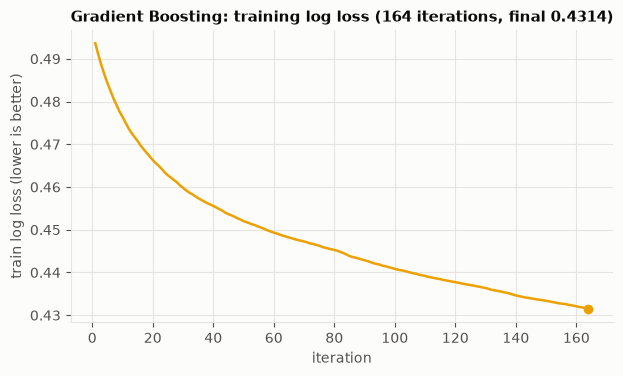

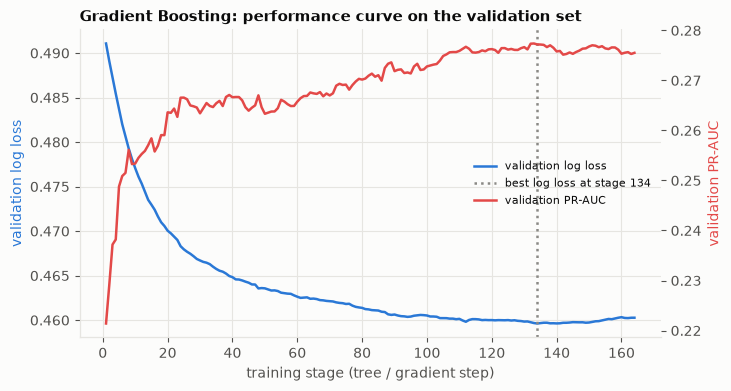

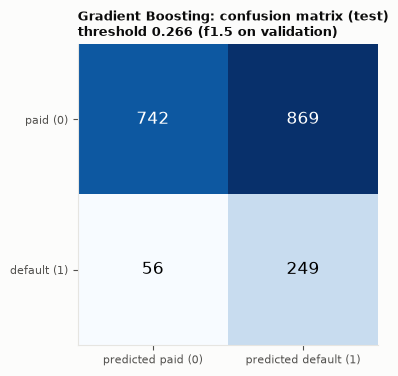

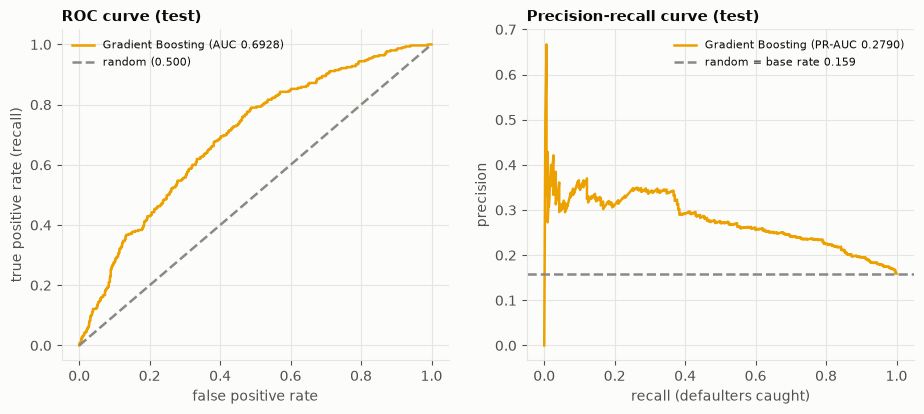

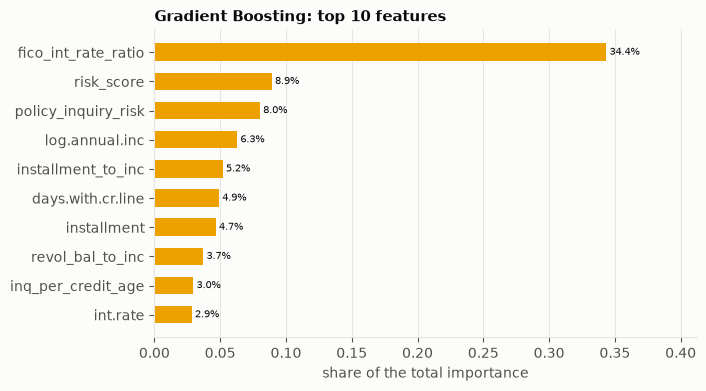


scratch vs library:
  Gradient Boosting vs sklearn GradientBoostingClassifier
    AUC scratch 0.6928 | AUC library 0.6664 | max |dP| = 0.371



saved + reloaded TrainedModels/Classification/04_Gradient_Boosting.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Gradient Boosting", model, d, check)